# Off-fault seismic moment vs. the geodetic rate: a maximum-magnitude sensitivity sweep

**Null hypothesis (H0):** the off-fault (>5 km from any mapped NSHM fault plane) moment rate estimated from our inversion (within the California model polygon),
`mu0 = 1.467968e19 N*m/yr`, is released entirely as off-fault seismicity.

**Aproach:**

1. **Spatial filter**: earthquakes are restricted to the California model domain
   (`California_strain_polygon.gmt`), shown in Fig. 4.
2. **Distance threshold**: All earthquakes within 5 km from any fault plane in 3-D are considered off-fault earthquakes.
3. **Maximum-magnitude handling**: rather than trying to statistically estimate a
   corner magnitude / Mmax from a data-poor tail, we fit only the power-law slope `beta` from the well-sampled bulk
   (above a minimum magnitude chosen by KS-minimization) and then
   **sweep** the assumed maximum magnitude from the largest off-fault event actually
   observed (Mw 6.6) up to Mw 7.6, UCERF3's expected maximum off-fault 
   earthquake magnitude.

| symbol | meaning |
|---|---|
| `MIN_FIT_MAGNITUDE` (= completeness, KS-selected) | lower magnitude of the fit, moment `Mt` |
| $M_{cm}$ | **corner** magnitude / moment of the **tapered Pareto**, a soft, exponential roll-off; events above it are possible, just exponentially rarer |
| $M_{max}$ | **maximum** magnitude of the **truncated GR**, a hard upper bound; probability is exactly zero above it |

---
> **Saved Monte Carlo results.** Every Monte Carlo run in this notebook is stored in
> `mc_cache/` (one compressed `.npz` per run, named after the run and a hash of its inputs).
> On a rerun a saved result is loaded instead of resampled, as long as all of its inputs
> (β, Mmax or corner moment, Mt, μ0·T, number of draws, seed) are unchanged; changing any of them
> triggers a fresh run automatically. Set `MC_CACHE_MODE` in Section 0 to control this.
> The inputs of the final figure are also saved (`mc_cache/figure_inputs.npz`), so
> **Section 12 can be run on its own in a fresh kernel** to redraw the figure without
> running anything above it.

## 0. Setup

In [1]:
import pickle
import numpy as np
import h5py
from scipy import optimize, special, stats
from matplotlib.path import Path
import matplotlib.pyplot as plt
import matplotlib as mpl

MC_SEED = 20240915
rng = np.random.default_rng(MC_SEED)

# --- Monte Carlo result cache -------------------------------------------------------------
# "auto"  : load a saved result if one exists for exactly these inputs; otherwise sample and save it
# "rerun" : always sample, and overwrite the saved results
# "off"   : always sample, and save nothing
# "load"  : only load the saved results shipped in Input_data/mc_cache; never sample (error if missing)
MC_CACHE_MODE = "load"
MC_CACHE_DIR = "../Input_data/mc_cache"   # saved Monte Carlo results 

# --- Paths for the self-contained supplement (run this notebook from Natgeo_supplements/Notebooks) ---
import os
INPUT_DIR = "../Input_data/focal_mechanisms"
OUTPUT_DIR = "../output_data/off_fault_moment_seismic_final"
FIG_OUT = os.path.join(OUTPUT_DIR, "figures")
os.makedirs(FIG_OUT, exist_ok=True)
MOMENT_MAGNITUDE_CONSTANT = 9.1   # log10(M0 [N*m]) = 1.5*Mw + 9.1

def mag_to_moment(mag):
    return 10.0 ** (1.5 * mag + MOMENT_MAGNITUDE_CONSTANT)

def moment_to_mag(moment):
    return (np.log10(moment) - MOMENT_MAGNITUDE_CONSTANT) / 1.5

## 1. Inputs

* `pickle_files/focmec_ca_final.pickle`, the original catalog: event longitude/latitude
  and origin times (for the polygon test and the time span). If it is absent, the notebook
  falls back to `focmec_ca_coordinates.mat`, which carries the same relocated coordinates
  but no origin times.
* `focmec_ca_nearest_fault_plane.mat`, output of
  `compute_earthquake_fault_plane_distances.m` (included in the distribution);
  we reuse `distance_to_fault_plane_km` and `magnitude` rather than recomputing the
  fault-plane geometry.
* `California_strain_polygon.gmt`, a simple two-column lon/lat polygon (included in
  the distribution), used to restrict the catalog to the California model domain.

In [2]:
import os
import scipy.io as sio

PICKLE_PATH = os.path.join(INPUT_DIR, "pickle_files", "focmec_ca_final.pickle")   # original catalog
COORD_MAT_PATH = os.path.join(INPUT_DIR, "focmec_ca_coordinates.mat")   # distributed cache (lon/lat/mag, no origin times)
MAT_OUTPUT_PATH = os.path.join(INPUT_DIR, "focmec_ca_nearest_fault_plane.mat")
POLYGON_PATH = os.path.join(INPUT_DIR, "California_strain_polygon.gmt")

with h5py.File(MAT_OUTPUT_PATH, "r") as f:
    dist_km = np.array(f["distance_to_fault_plane_km"]).ravel()
    magnitude = np.array(f["magnitude"]).ravel()

if os.path.exists(PICKLE_PATH):
    with open(PICKLE_PATH, "rb") as fh:
        catalog = pickle.load(fh)
    lon = np.asarray(catalog["lon_reloc"], dtype=float)   # matches use_relocated_coordinates=true
    lat = np.asarray(catalog["lat_reloc"], dtype=float)   # in the MATLAB script's default config
    assert np.allclose(np.asarray(catalog["mag"], dtype=float), magnitude, equal_nan=True), "Row order mismatch."
    print(f"Catalog loaded from {PICKLE_PATH} ({lon.size:,} events)")
else:
    catalog = None
    coords = sio.loadmat(COORD_MAT_PATH)
    lon = coords["lon_reloc"].ravel()
    lat = coords["lat_reloc"].ravel()
    assert np.allclose(coords["mag"].ravel(), magnitude, equal_nan=True), "Row order mismatch."
    print(f"Pickle not found -> using {COORD_MAT_PATH}")

assert dist_km.size == magnitude.size == lon.size, "Row-count mismatch between inputs."
moment_nm = mag_to_moment(magnitude)

Catalog loaded from ../Input_data/focal_mechanisms/pickle_files/focmec_ca_final.pickle (1,574,113 events)


/var/folders/n2/w17y8ykn2rn31lc0sxzrmh0rmbh4zs/T/ipykernel_58020/21972162.py:15: DeprecationWarning: numpy.core.numeric is deprecated and has been renamed to numpy._core.numeric. The numpy._core namespace contains private NumPy internals and its use is discouraged, as NumPy internals can change without warning in any release. In practice, most real-world usage of numpy.core is to access functionality in the public NumPy API. If that is the case, use the public NumPy API. If not, you are using NumPy internals. If you would still like to access an internal attribute, use numpy._core.numeric._frombuffer.
  catalog = pickle.load(fh)


## 2. Catalog time span

In [3]:
T_YEARS_FROM_PICKLE = 40.847   # 1981-01-01 to 2021-11-06, computed from catalog["time_utc"] (see methods)

if catalog is not None:
    time_utc = np.asarray(catalog["time_utc"], dtype=float)
    T_years_exact = (time_utc.max() - time_utc.min()) / 86400.0 / 365.25
    print(f"Catalog span: {T_years_exact:.5f} years ({np.min(catalog['year']):.0f}-{np.max(catalog['year']):.0f})")
    # The published results and the saved Monte Carlo runs in Input_data/mc_cache use the span
    # rounded to 40.847 yr (the budget mu0*T enters the cache key), so the rounded value is kept.
    assert abs(T_years_exact - T_YEARS_FROM_PICKLE) < 1e-3, T_years_exact
    T_years = T_YEARS_FROM_PICKLE
    print(f"Using T = {T_years:.3f} years (rounded value used for the published results)")
else:
    T_years = T_YEARS_FROM_PICKLE
    print(f"Catalog span (from the original catalog, origin times not in the MAT cache): {T_years:.3f} years")

Catalog span: 40.84655 years (1981-2021)
Using T = 40.847 years (rounded value used for the published results)


## 3. Spatial filter: California strain polygon

The polygon is a single closed ring in longitude/latitude; we use a standard
point-in-polygon test (`matplotlib.path.Path`).

In [4]:
polygon_lonlat = np.loadtxt(POLYGON_PATH)
polygon_path = Path(polygon_lonlat)
in_polygon = polygon_path.contains_points(np.column_stack([lon, lat]))
print(f"Events inside the California strain polygon: {in_polygon.sum():,} / {in_polygon.size:,} "
      f"({in_polygon.mean():.2%})")

Events inside the California strain polygon: 1,540,664 / 1,574,113 (97.88%)


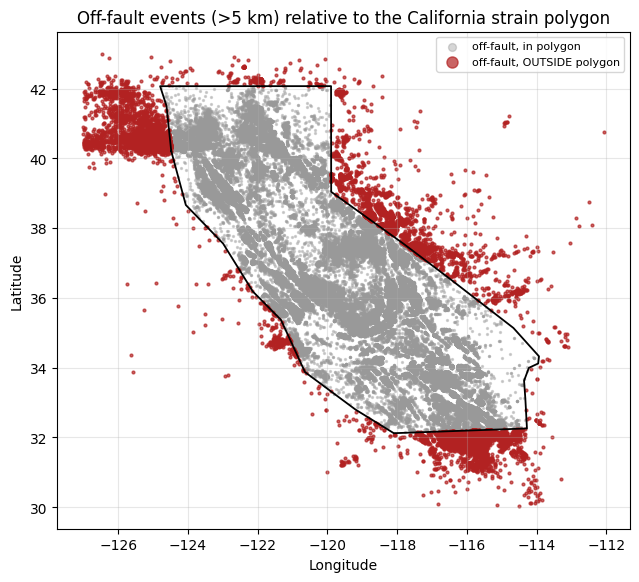

In [5]:
far_off_fault = dist_km > 5.0
fig, ax = plt.subplots(figsize=(6.5, 6))
ax.scatter(lon[far_off_fault & in_polygon], lat[far_off_fault & in_polygon],
           s=2, color="0.6", alpha=0.4, label="off-fault, in polygon")
ax.scatter(lon[far_off_fault & ~in_polygon], lat[far_off_fault & ~in_polygon],
           s=4, color="firebrick", alpha=0.7, label="off-fault, OUTSIDE polygon")
ax.plot(np.append(polygon_lonlat[:, 0], polygon_lonlat[0, 0]),
        np.append(polygon_lonlat[:, 1], polygon_lonlat[0, 1]), "k-", lw=1.3)
ax.set_xlabel("Longitude"); ax.set_ylabel("Latitude")
ax.set_title("Off-fault events (>5 km) relative to the California strain polygon")
ax.legend(markerscale=4, fontsize=8); ax.set_aspect("equal"); ax.grid(alpha=0.3)
plt.tight_layout()
fig.savefig(os.path.join(FIG_OUT, "offfault_events_polygon.png"), dpi=300, bbox_inches="tight")

## 4. Off-fault seismic moment at the 5 km threshold, inside the polygon

In [6]:
DIST_THRESH_KM = 5.0
off_fault = (dist_km > DIST_THRESH_KM) & in_polygon

n_off = int(off_fault.sum())
M_obs = moment_nm[off_fault].sum()
max_obs_mag = magnitude[off_fault].max()

print(f"Off-fault (> {DIST_THRESH_KM:g} km, in-polygon) events:  {n_off:,}")
print(f"Off-fault total seismic moment:                 {M_obs:.4e} N*m")
print(f"Implied off-fault moment RATE:                   {M_obs/T_years:.4e} N*m/yr")
print(f"Largest off-fault event observed:                Mw {max_obs_mag:.2f}")

Off-fault (> 5 km, in-polygon) events:  492,442
Off-fault total seismic moment:                 3.5383e+19 N*m
Implied off-fault moment RATE:                   8.6622e+17 N*m/yr
Largest off-fault event observed:                Mw 6.58


## 5. Choosing the minimum fitting magnitude


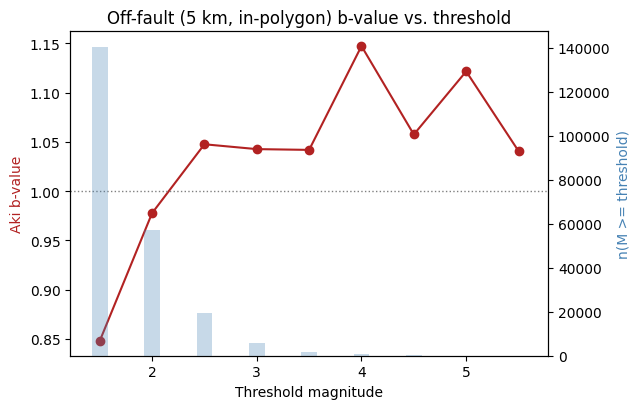

In [7]:
def aki_b(mags, mc):
    x = mags[mags >= mc]
    if x.size < 5:
        return np.nan, x.size
    return 1.0 / (np.log(10.0) * (x.mean() - mc)), x.size

mc_grid = np.array([1.5, 2.0, 2.5, 3.0, 3.5, 4.0, 4.5, 5.0, 5.5])
b_vals, n_vals = zip(*[aki_b(magnitude[off_fault], mc) for mc in mc_grid])

fig, ax1 = plt.subplots(figsize=(6.5, 4.2))
ax1.plot(mc_grid, b_vals, "o-", color="firebrick")
ax1.set_xlabel("Threshold magnitude"); ax1.set_ylabel("Aki b-value", color="firebrick")
ax1.axhline(1.0, color="0.5", ls=":", lw=1)
ax2 = ax1.twinx()
ax2.bar(mc_grid, n_vals, width=0.15, color="steelblue", alpha=0.3)
ax2.set_ylabel("n(M >= threshold)", color="steelblue")
ax1.set_title("Off-fault (5 km, in-polygon) b-value vs. threshold")
plt.tight_layout()
fig.savefig(os.path.join(FIG_OUT, "bvalue_vs_threshold.png"), dpi=300, bbox_inches="tight")

### 5.1 Completeness magnitude by KS-minimization

KS-minimizing completeness magnitude: Mc = 2.60  (n = 15,256, beta = 0.7004)


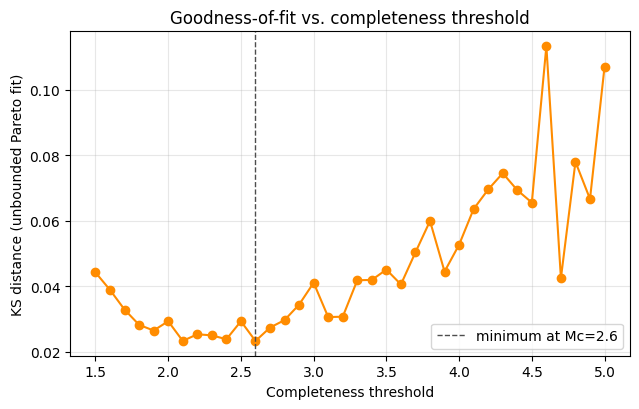

In [8]:
def ks_distance_pareto(m, Mt, beta):
    ms = np.sort(m); n = ms.size
    F_emp = np.arange(1, n + 1) / n
    F_fit = 1.0 - (ms / Mt) ** (-beta)
    return np.max(np.maximum(np.abs(F_emp - F_fit), np.abs(F_emp - 1.0 / n - F_fit)))

mc_scan = np.round(np.arange(1.5, 5.01, 0.1), 2)
ks_values, beta_scan, n_scan = [], [], []
for mc_trial in mc_scan:
    Mt_trial = mag_to_moment(mc_trial)
    m_trial = moment_nm[off_fault & (magnitude >= mc_trial)]
    if m_trial.size < 30:
        ks_values.append(np.nan); beta_scan.append(np.nan); n_scan.append(m_trial.size); continue
    beta_trial = m_trial.size / np.sum(np.log(m_trial / Mt_trial))
    ks_values.append(ks_distance_pareto(m_trial, Mt_trial, beta_trial))
    beta_scan.append(beta_trial); n_scan.append(m_trial.size)
ks_values = np.array(ks_values)

Mc_computed = float(mc_scan[np.nanargmin(ks_values)])
print(f"KS-minimizing completeness magnitude: Mc = {Mc_computed:.2f}  "
      f"(n = {n_scan[np.nanargmin(ks_values)]:,}, beta = {beta_scan[np.nanargmin(ks_values)]:.4f})")

fig, ax = plt.subplots(figsize=(6.5, 4.2))
ax.plot(mc_scan, ks_values, "o-", color="darkorange")
ax.axvline(Mc_computed, color="0.3", ls="--", lw=1, label=f"minimum at Mc={Mc_computed:.1f}")
ax.set_xlabel("Completeness threshold"); ax.set_ylabel("KS distance (unbounded Pareto fit)")
ax.set_title("Goodness-of-fit vs. completeness threshold")
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout()
fig.savefig(os.path.join(FIG_OUT, "ks_vs_completeness.png"), dpi=300, bbox_inches="tight")

In [9]:
MIN_FIT_MAGNITUDE = Mc_computed   

Mt = mag_to_moment(MIN_FIT_MAGNITUDE)
m_fit = moment_nm[off_fault & (magnitude >= MIN_FIT_MAGNITUDE)]
n_fit = m_fit.size
M_below_Mt = M_obs - m_fit.sum()
print(f"MIN_FIT_MAGNITUDE = {MIN_FIT_MAGNITUDE}   Mt = {Mt:.4e} N*m   n(M>=Mt) = {n_fit}")
print(f"Sub-threshold moment (fixed additive term) = {M_below_Mt:.3e} N*m "
      f"({M_below_Mt/M_obs:.2%} of total)")

MIN_FIT_MAGNITUDE = 2.6   Mt = 1.0000e+13 N*m   n(M>=Mt) = 15256
Sub-threshold moment (fixed additive term) = 2.027e+17 N*m (0.57% of total)


## 6. Fitting the power-law slope `beta`

We fit only `beta`, the Pareto index shared by both models' power-law body,
using the closed-form maximum-likelihood estimator for an unbounded Pareto:
$\hat\beta = n \big/ \sum_i \ln(m_i/M_t)$. The tail parameter (corner magnitude /
`Mmax`) is *not* fit; see Section 7.

In [10]:
beta_hat = n_fit / np.sum(np.log(m_fit / Mt))
b_value = 1.5 * beta_hat
print(f"beta = {beta_hat:.4f}  (b-value = {b_value:.4f}, n = {n_fit})")

beta = 0.7004  (b-value = 1.0505, n = 15256)


### 6.1 Should `beta` be fit once, or separately for every `Mmax` in the sweep?

The sweep is designed to isolate one question, sensitivity to the (poorly
constrained) maximum magnitude, while holding fixed the part of the model the data
*do* constrain well: the body of the FMD above `MIN_FIT_MAGNITUDE`. **What we do:
fit `beta` once, from the unbounded estimator above, and hold it fixed across
the whole sweep.** 

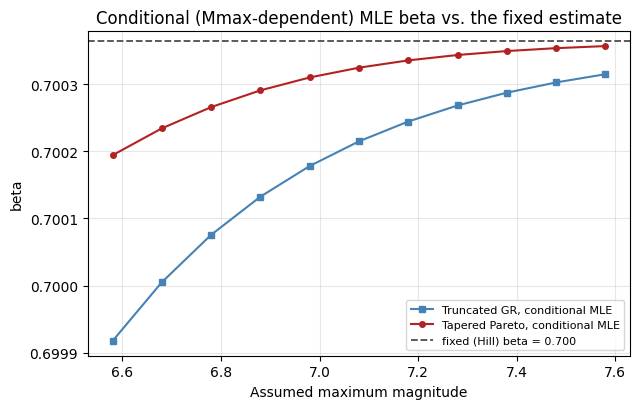

In [11]:
def truncgr_negloglik_beta(beta, m, Mt, Mmax):
    r = Mt / Mmax
    logC = np.log(beta) + beta * np.log(Mt) - np.log(1 - r ** beta)
    return -np.sum(logC - (beta + 1) * np.log(m))

def tapered_negloglik_beta(beta, m, Mt, Mc_corner):
    x = m / Mt
    logS = -beta * np.log(x) + (Mt - m) / Mc_corner
    return -np.sum(logS + np.log(beta / m + 1.0 / Mc_corner))

def conditional_beta_truncgr(m, Mt, Mmax):
    r = optimize.minimize_scalar(truncgr_negloglik_beta, args=(m, Mt, Mmax),
                                  bounds=(0.05, 3.0), method="bounded", options=dict(xatol=1e-10))
    return r.x

def conditional_beta_tapered(m, Mt, Mc_corner):
    r = optimize.minimize_scalar(tapered_negloglik_beta, args=(m, Mt, Mc_corner),
                                  bounds=(0.05, 3.0), method="bounded", options=dict(xatol=1e-10))
    return r.x

_check_grid = np.round(np.arange(max_obs_mag, 7.6 + 1e-9, 0.1), 2)
beta_cond_tgr = [conditional_beta_truncgr(m_fit, Mt, mag_to_moment(mm)) for mm in _check_grid]
beta_cond_tp = [conditional_beta_tapered(m_fit, Mt, mag_to_moment(mm)) for mm in _check_grid]

fig, ax = plt.subplots(figsize=(6.5, 4.2))
ax.plot(_check_grid, beta_cond_tgr, "-s", ms=4, color="steelblue", label="Truncated GR, conditional MLE")
ax.plot(_check_grid, beta_cond_tp, "-o", ms=4, color="firebrick", label="Tapered Pareto, conditional MLE")
ax.axhline(beta_hat, color="0.3", ls="--", lw=1.3, label=f"fixed (Hill) beta = {beta_hat:.3f}")
ax.set_xlabel("Assumed maximum magnitude"); ax.set_ylabel("beta")
ax.set_title("Conditional (Mmax-dependent) MLE beta vs. the fixed estimate")
ax.legend(fontsize=8); ax.grid(alpha=0.3)
plt.tight_layout()
fig.savefig(os.path.join(FIG_OUT, "conditional_beta_vs_mmax.png"), dpi=300, bbox_inches="tight")

The conditional estimates converge to the fixed (Hill) value as `Mmax` grows (as
expected, the truncation effect vanishes for `Mmax >> Mt`), but sit meaningfully
lower at the tight end, where `Mmax` is pinned close to the one event that actually
defines the observed maximum. We carry the **fixed beta** forward as the primary
analysis (Sections 7-10), and revisit the conditional
version as an explicit robustness check in Section 9.4.

## 7. Sweeping the maximum magnitude

For each assumed maximum magnitude `Mmax_mag` from the observed off-fault maximum up to
Mw 7.6 (UCERF3's expected maximum off-fault earthquake magnitude) in steps
of 0.1, we build:

* a **Truncated GR** survival function with a hard cutoff at `Mmax_mag`, and
* a **Tapered Pareto** survival function using `Mmax_mag` as the corner magnitude
  (the tapered model has no hard cutoff, but the corner magnitude plays the analogous
  role of setting where the exponential taper takes over from the power law),

both sharing the same `beta` fit above.

In [12]:
UCERF3_MAX_OFF_FAULT_MW = 7.6

mmax_grid = np.round(np.arange(max_obs_mag, UCERF3_MAX_OFF_FAULT_MW + 1e-9, 0.1), 2)
if mmax_grid[-1] < UCERF3_MAX_OFF_FAULT_MW - 1e-6:
    mmax_grid = np.append(mmax_grid, UCERF3_MAX_OFF_FAULT_MW)
print(f"Sweep: {mmax_grid[0]:.2f} to {mmax_grid[-1]:.2f} Mw, {len(mmax_grid)} steps")

def raw_moment_tapered(p, Mt, beta, Mc_corner):
    term1 = Mt ** p
    term2 = (p * Mt ** beta * Mc_corner ** (p - beta) * np.exp(Mt / Mc_corner)
             * special.gammaincc(p - beta, Mt / Mc_corner) * special.gamma(p - beta))
    return term1 + term2

def raw_moment_truncgr(p, Mt, beta, Mmax):
    r = Mt / Mmax
    if abs(beta - p) < 1e-9:
        num = beta * Mt ** beta * np.log(Mmax / Mt)
    else:
        num = beta * Mt ** beta / (p - beta) * (Mmax ** (p - beta) - Mt ** (p - beta))
    return num / (1 - r ** beta)

def S_tapered(mm, Mt, beta, Mc_corner):
    return (mm / Mt) ** (-beta) * np.exp((Mt - mm) / Mc_corner)

def S_truncgr(mm, Mt, beta, Mmax):
    r = Mt / Mmax
    return ((Mt / mm) ** beta - r ** beta) / (1 - r ** beta)

sweep = []
for mmax_mag in mmax_grid:
    Mmax_moment = mag_to_moment(mmax_mag)
    EM_tp = raw_moment_tapered(1.0, Mt, beta_hat, Mmax_moment)
    EM2_tp = raw_moment_tapered(2.0, Mt, beta_hat, Mmax_moment)
    EM_tgr = raw_moment_truncgr(1.0, Mt, beta_hat, Mmax_moment)
    EM2_tgr = raw_moment_truncgr(2.0, Mt, beta_hat, Mmax_moment)
    sweep.append(dict(mmax_mag=mmax_mag, Mmax_moment=Mmax_moment,
                       EM_tp=EM_tp, EM2_tp=EM2_tp, EM_tgr=EM_tgr, EM2_tgr=EM2_tgr))

Sweep: 6.58 to 7.60 Mw, 12 steps


## 8. The sweep plot: fitted distribution families vs. the observed off-fault data

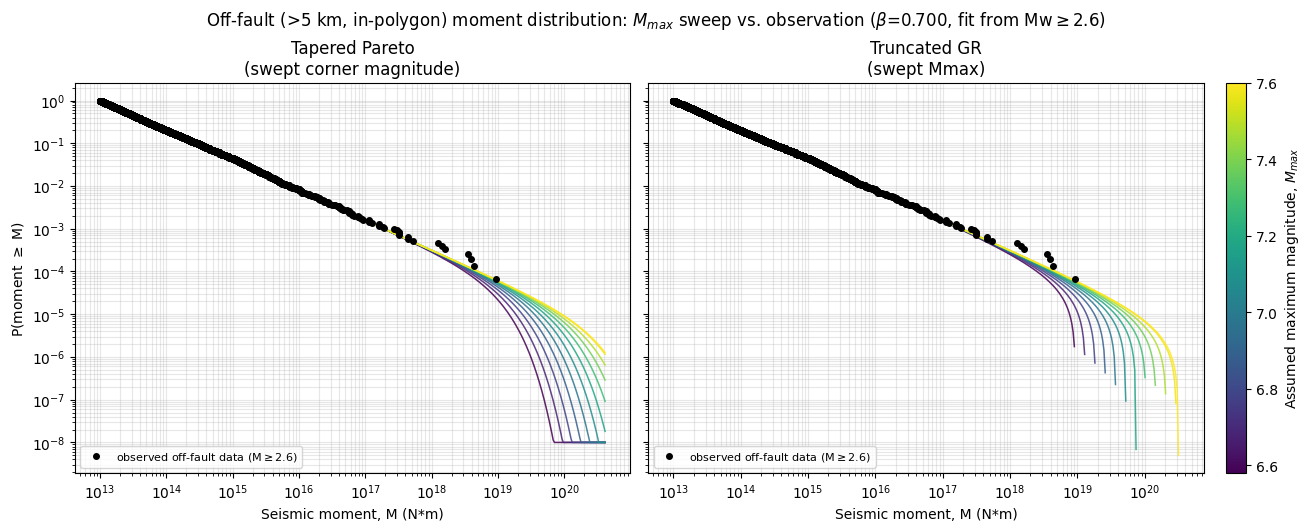

In [13]:
cmap = mpl.cm.viridis

norm = mpl.colors.Normalize(
    vmin=mmax_grid[0],
    vmax=mmax_grid[-1]
)

grid_moments = np.geomspace(
    Mt,
    mag_to_moment(UCERF3_MAX_OFF_FAULT_MW) * 1.3,
    400
)

m_sorted = np.sort(m_fit)[::-1]

surv_emp = np.arange(1, n_fit + 1) / n_fit

fig, axes = plt.subplots(
    1,
    2,
    figsize=(13, 5.2),
    sharey=True,
    constrained_layout=True
)

for row in sweep:

    color = cmap(norm(row["mmax_mag"]))

    # Tapered Pareto
    s_tp = S_tapered(
        grid_moments,
        Mt,
        beta_hat,
        row["Mmax_moment"]
    )

    axes[0].loglog(
        grid_moments,
        np.clip(s_tp, 1e-8, None),
        color=color,
        lw=1.1,
        alpha=0.85
    )

    # Truncated Gutenberg-Richter
    valid = grid_moments <= row["Mmax_moment"]

    s_tgr = S_truncgr(
        grid_moments[valid],
        Mt,
        beta_hat,
        row["Mmax_moment"]
    )

    axes[1].loglog(
        grid_moments[valid],
        s_tgr,
        color=color,
        lw=1.1,
        alpha=0.85
    )


# Add empirical survival distribution to both panels
for ax, title in zip(
    axes,
    [
        "Tapered Pareto\n(swept corner magnitude)",
        "Truncated GR\n(swept Mmax)"
    ]
):

    ax.loglog(
        m_sorted,
        surv_emp,
        "o",
        ms=4,
        color="black",
        zorder=5,
        label=(
            f"observed off-fault data "
            f"(M$\\geq${MIN_FIT_MAGNITUDE:g})"
        )
    )

    ax.set_xlabel("Seismic moment, M (N*m)")
    ax.set_title(title)

    ax.grid(
        alpha=0.3,
        which="both"
    )

    ax.legend(
        loc="lower left",
        fontsize=8
    )


# Shared y-axis label
axes[0].set_ylabel("P(moment $\\geq$ M)")


# Colorbar for assumed maximum magnitude
sm = mpl.cm.ScalarMappable(
    cmap=cmap,
    norm=norm
)

sm.set_array([])

cbar = fig.colorbar(
    sm,
    ax=axes,
    orientation="vertical",
    fraction=0.03,
    pad=0.02
)

cbar.set_label(
    "Assumed maximum magnitude, $M_{max}$"
)


# Overall figure title
fig.suptitle(
    f"Off-fault (>{DIST_THRESH_KM:g} km, in-polygon) moment distribution: "
    f"$M_{{max}}$ sweep vs. observation "
    f"($\\beta$={beta_hat:.3f}, "
    f"fit from Mw$\\geq${MIN_FIT_MAGNITUDE:g})"
)

fig.savefig(os.path.join(FIG_OUT, "moment_ccdf_mmax_sweep.png"), dpi=300, bbox_inches="tight")
plt.show()

## 9. Null-hypothesis test across the sweep

For each assumed `Mmax`, `E[M]` sets the Poisson event rate needed to reproduce the
null moment budget `M_G = mu0*T` (`mu0 = 1.467968e19  N*m/yr`, off-fault-specific), and
`Var[M] = E[M^2]-E[M]^2` sets the width of the resulting sampling distribution of the
T-year total off-fault moment. We use the closed-form Normal (CLT) approximation here
(fast enough to cover the whole sweep in closed form) and validate it against a true
event-level Monte Carlo at one representative point below.

In [14]:
MU0 = 1.467968e19  # off-fault geodetic moment rate, N*m/yr (this is the median representative model, see methods in our paper for details)
M_G_null = MU0 * T_years

def analytic_test(EM, EM2):
    n_null = M_G_null / EM
    mean_S = n_null * EM + M_below_Mt
    std_S = np.sqrt(n_null * (EM2 - EM ** 2 + EM ** 2))   # = sqrt(n_null * EM2)
    z = (M_obs - mean_S) / std_S
    return n_null, mean_S, std_S, z, stats.norm.cdf(z)

for row in sweep:
    row["n_null_tp"], row["mean_S_tp"], row["std_S_tp"], row["z_tp"], row["p_tp"] = analytic_test(row["EM_tp"], row["EM2_tp"])
    row["n_null_tgr"], row["mean_S_tgr"], row["std_S_tgr"], row["z_tgr"], row["p_tgr"] = analytic_test(row["EM_tgr"], row["EM2_tgr"])

print(f"R = observed/expected = {M_obs/sweep[0]['mean_S_tp']:.3f} at Mmax={sweep[0]['mmax_mag']:.2f} "
      f"(R is essentially independent of Mmax and model)")
print(f"{'Mmax':>6}  {'p (Tapered Pareto)':>20}  {'p (Truncated GR)':>18}")
for row in sweep:
    print(f"{row['mmax_mag']:6.2f}  {row['p_tp']:20.4f}  {row['p_tgr']:18.4f}")

R = observed/expected = 0.059 at Mmax=6.58 (R is essentially independent of Mmax and model)
  Mmax    p (Tapered Pareto)    p (Truncated GR)
  6.58                0.0000              0.0000
  6.68                0.0000              0.0000
  6.78                0.0000              0.0000
  6.88                0.0000              0.0000
  6.98                0.0000              0.0000
  7.08                0.0000              0.0000
  7.18                0.0003              0.0000
  7.28                0.0019              0.0000
  7.38                0.0073              0.0000
  7.48                0.0199              0.0005
  7.58                0.0419              0.0027
  7.60                0.0474              0.0036


### 9.1 Validating the Normal approximation with a true Monte Carlo run

We spot-check at `Mmax = 7.6` (the heaviest-tailed, and therefore most CLT-favorable,
point in the sweep) and at the observed maximum (the lightest-tailed, least
CLT-favorable point) by actually sampling synthetic catalogs event-by-event.

In [15]:
def sample_tapered_pareto(n, Mt, beta, Mc_corner, rng):
    C = np.exp(beta - 1.0) / beta
    out = np.empty(n); filled = 0
    while filled < n:
        need = n - filled
        batch = int(need * 1.05 * C) + 1000
        u = rng.random(batch)
        cand = Mt * u ** (-1.0 / beta)
        h = np.exp((Mt - cand) / Mc_corner) * (1.0 + cand / (beta * Mc_corner))
        keep = cand[rng.random(batch) < h / C]
        take = min(keep.size, need)
        out[filled:filled + take] = keep[:take]
        filled += take
    return out

def sample_truncated_gr(n, Mt, beta, Mmax, rng):
    r = Mt / Mmax
    u = rng.random(n)
    return Mt / (1.0 - u * (1.0 - r ** beta)) ** (1.0 / beta)

def monte_carlo_totals(sampler, Mt, EM, extra_args, n_mc, rng=rng):
    n_null = M_G_null / EM
    n_sim = rng.poisson(n_null, size=n_mc)
    return np.array([
        (sampler(int(n_i), Mt, *extra_args, rng).sum() if n_i > 0 else 0.0) + M_below_Mt
        for n_i in n_sim
    ])

import hashlib, json, time

def cached_monte_carlo_totals(run_name, sampler, Mt, EM, extra_args, n_mc):
    """monte_carlo_totals() with results saved to / loaded from MC_CACHE_DIR.

    The file name carries a hash of every input that affects the draws, so a saved result is
    reused only when the inputs are identical. Each run gets its own random stream, seeded from
    MC_SEED and that hash, so results do not depend on which other runs were loaded or sampled.
    """
    assert MC_CACHE_MODE in ("auto", "rerun", "off", "load"), MC_CACHE_MODE
    fmt = lambda v: f"{float(v):.10e}"
    params = dict(run=run_name, sampler=sampler.__name__, Mt=fmt(Mt), EM=fmt(EM),
                  extra_args=[fmt(a) for a in extra_args], n_mc=int(n_mc),
                  M_G_null=fmt(M_G_null), M_below_Mt=fmt(M_below_Mt), seed=MC_SEED)
    digest = hashlib.sha1(json.dumps(params, sort_keys=True).encode()).hexdigest()[:12]
    path = os.path.join(MC_CACHE_DIR, f"{run_name}_{digest}.npz")

    if MC_CACHE_MODE in ("auto", "load") and os.path.exists(path):
        with np.load(path) as saved:
            return saved["totals"]
    if MC_CACHE_MODE == "load":
        raise FileNotFoundError(f"Saved Monte Carlo result not found: {path} "
                                "(set MC_CACHE_MODE = 'auto' to sample it)")

    t0 = time.time()
    totals = monte_carlo_totals(sampler, Mt, EM, extra_args, n_mc,
                                rng=np.random.default_rng([MC_SEED, int(digest, 16)]))
    if MC_CACHE_MODE != "off":
        os.makedirs(MC_CACHE_DIR, exist_ok=True)
        np.savez_compressed(path, totals=totals, params=json.dumps(params))
    print(f"  [MC] {run_name}: {n_mc:,} draws sampled in {time.time() - t0:.0f} s"
          + (f" -> saved to {path}" if MC_CACHE_MODE != "off" else ""))
    return totals

for check_row in (sweep[0], sweep[-1]):
    tot_tp = cached_monte_carlo_totals(f"check_tp_Mmax{check_row['mmax_mag']:.2f}", sample_tapered_pareto, Mt,
                                       check_row["EM_tp"], (beta_hat, check_row["Mmax_moment"]), 2000)
    tot_tgr = cached_monte_carlo_totals(f"check_tgr_Mmax{check_row['mmax_mag']:.2f}", sample_truncated_gr, Mt,
                                        check_row["EM_tgr"], (beta_hat, check_row["Mmax_moment"]), 2000)
    print(f"Mmax={check_row['mmax_mag']:.2f}:  "
          f"Tapered Pareto  MC p={(tot_tp<=M_obs).mean():.4f} vs Normal p={check_row['p_tp']:.4f}   |   "
          f"Truncated GR  MC p={(tot_tgr<=M_obs).mean():.4f} vs Normal p={check_row['p_tgr']:.4f}")

Mmax=6.58:  Tapered Pareto  MC p=0.0000 vs Normal p=0.0000   |   Truncated GR  MC p=0.0000 vs Normal p=0.0000
Mmax=7.60:  Tapered Pareto  MC p=0.0000 vs Normal p=0.0474   |   Truncated GR  MC p=0.0000 vs Normal p=0.0036


### 9.2 Full Monte Carlo across the sweep

In [16]:
N_MC_SWEEP = 10_000  # Zero exceedances out of this many draws is reported as p < 1/N_MC_SWEEP.

for row in sweep:
    row["tot_tp"] = cached_monte_carlo_totals(f"sweep_tp_Mmax{row['mmax_mag']:.2f}", sample_tapered_pareto, Mt,
                                              row["EM_tp"], (beta_hat, row["Mmax_moment"]), N_MC_SWEEP)
    row["tot_tgr"] = cached_monte_carlo_totals(f"sweep_tgr_Mmax{row['mmax_mag']:.2f}", sample_truncated_gr, Mt,
                                               row["EM_tgr"], (beta_hat, row["Mmax_moment"]), N_MC_SWEEP)
    row["p_mc_tp"] = (row["tot_tp"] <= M_obs).mean()
    row["p_mc_tgr"] = (row["tot_tgr"] <= M_obs).mean()
    row["n_below_tp"] = int((row["tot_tp"] <= M_obs).sum())
    row["n_below_tgr"] = int((row["tot_tgr"] <= M_obs).sum())

print(f"{'Mmax':>6}  {'p (Tapered Pareto)':>22}  {'p (Truncated GR)':>20}")
for row in sweep:
    ptp = f"{row['p_mc_tp']:.5f}" if row["n_below_tp"] > 0 else f"< {1/N_MC_SWEEP:.1e}"
    ptgr = f"{row['p_mc_tgr']:.5f}" if row["n_below_tgr"] > 0 else f"< {1/N_MC_SWEEP:.1e}"
    print(f"{row['mmax_mag']:6.2f}  {ptp:>22}  {ptgr:>20}")

  Mmax      p (Tapered Pareto)      p (Truncated GR)
  6.58               < 1.0e-04             < 1.0e-04
  6.68               < 1.0e-04             < 1.0e-04
  6.78               < 1.0e-04             < 1.0e-04
  6.88               < 1.0e-04             < 1.0e-04
  6.98               < 1.0e-04             < 1.0e-04
  7.08               < 1.0e-04             < 1.0e-04
  7.18               < 1.0e-04             < 1.0e-04
  7.28               < 1.0e-04             < 1.0e-04
  7.38               < 1.0e-04             < 1.0e-04
  7.48               < 1.0e-04             < 1.0e-04
  7.58               < 1.0e-04             < 1.0e-04
  7.60               < 1.0e-04             < 1.0e-04


### Sampled distribution vs. the observation

The histograms below show what the sweep's p-values are actually reading off: the
Monte Carlo-sampled distribution of the 40-year off-fault total under H0, at three
representative points across the sweep, with the observed total marked as a vertical
line.

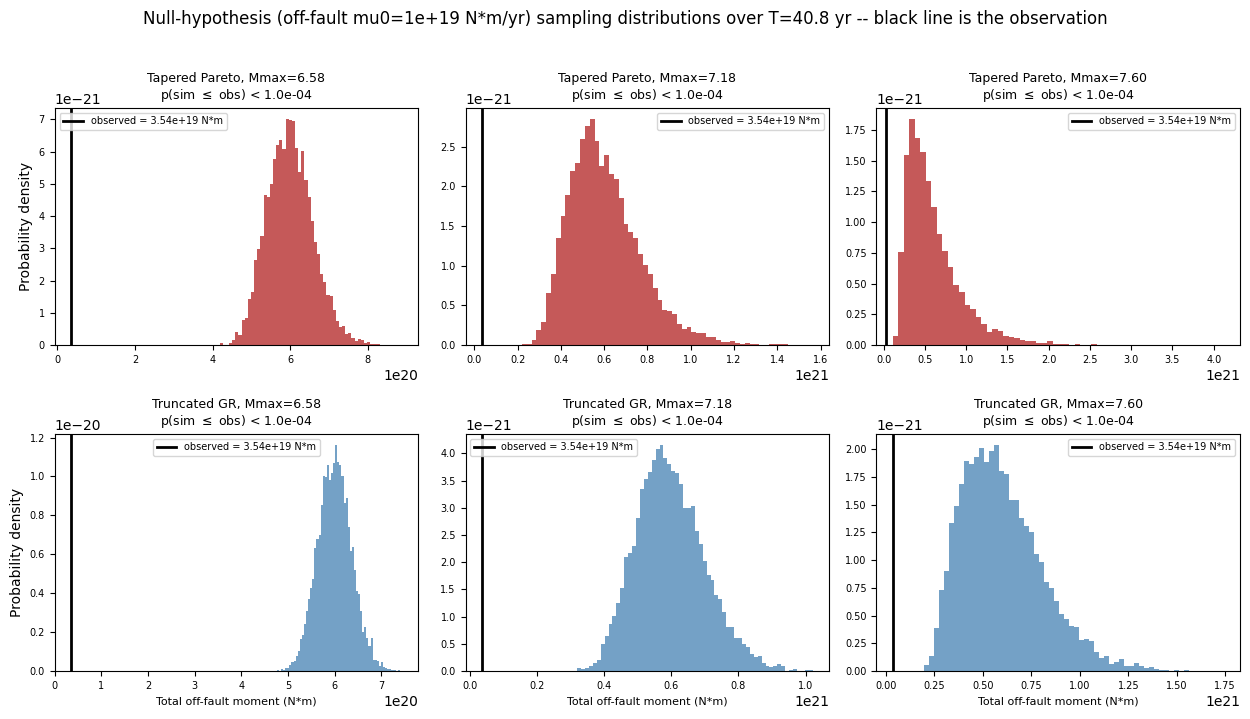

In [17]:
pick_idx = sorted(set([0, len(sweep) // 2, len(sweep) - 1]))
fig, axes = plt.subplots(2, len(pick_idx), figsize=(4.2 * len(pick_idx), 7), sharex=False)
for col, idx in enumerate(pick_idx):
    row = sweep[idx]
    for r, (model_name, tot, color) in enumerate([
        ("Tapered Pareto", row["tot_tp"], "firebrick"),
        ("Truncated GR", row["tot_tgr"], "steelblue"),
    ]):
        ax = axes[r, col]
        ax.hist(tot, bins=60, color=color, alpha=0.75, density=True)
        ax.axvline(M_obs, color="k", lw=2, label=f"observed = {M_obs:.2e} N*m")
        p_val = row["p_mc_tp"] if r == 0 else row["p_mc_tgr"]
        n_below = row["n_below_tp"] if r == 0 else row["n_below_tgr"]
        p_label = f"{p_val:.4f}" if n_below > 0 else f"< {1/N_MC_SWEEP:.1e}"
        ax.set_title(f"{model_name}, Mmax={row['mmax_mag']:.2f}\np(sim $\\leq$ obs) {p_label}", fontsize=9)
        if r == 1:
            ax.set_xlabel("Total off-fault moment (N*m)", fontsize=8)
        if col == 0:
            ax.set_ylabel("Probability density")
        ax.legend(fontsize=7)
        ax.tick_params(labelsize=7)
plt.suptitle(f"Null-hypothesis (off-fault mu0={MU0:.0e} N*m/yr) sampling distributions over "
             f"T={T_years:.1f} yr -- black line is the observation", y=1.02)
plt.tight_layout()
fig.savefig(os.path.join(FIG_OUT, "null_sampling_distributions.png"), dpi=300, bbox_inches="tight")

### 9.3 R and p-value vs. assumed maximum magnitude

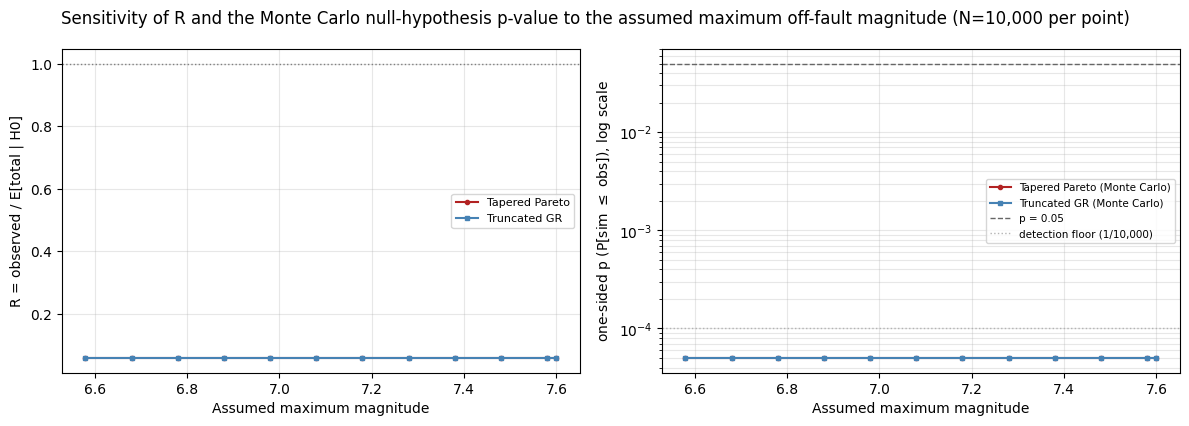

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.3))
mmax_vals = [row["mmax_mag"] for row in sweep]

axes[0].plot(mmax_vals, [M_obs / row["mean_S_tp"] for row in sweep], "-o", ms=3,
             color="firebrick", label="Tapered Pareto")
axes[0].plot(mmax_vals, [M_obs / row["mean_S_tgr"] for row in sweep], "-s", ms=3,
             color="steelblue", label="Truncated GR")
axes[0].axhline(1.0, color="0.5", ls=":", lw=1)
axes[0].set_xlabel("Assumed maximum magnitude"); axes[0].set_ylabel("R = observed / E[total | H0]")
axes[0].legend(fontsize=8); axes[0].grid(alpha=0.3)

floor = 0.5 / N_MC_SWEEP  # plotting floor for zero-exceedance points (p < 1/N_MC_SWEEP)
p_tp_plot = [max(row["p_mc_tp"], floor) for row in sweep]
p_tgr_plot = [max(row["p_mc_tgr"], floor) for row in sweep]
axes[1].semilogy(mmax_vals, p_tp_plot, "-o", ms=3, color="firebrick", label="Tapered Pareto (Monte Carlo)")
axes[1].semilogy(mmax_vals, p_tgr_plot, "-s", ms=3, color="steelblue", label="Truncated GR (Monte Carlo)")
axes[1].axhline(0.05, color="0.4", ls="--", lw=1, label="p = 0.05")
axes[1].axhline(1 / N_MC_SWEEP, color="0.7", ls=":", lw=1, label=f"detection floor (1/{N_MC_SWEEP:,})")
axes[1].set_xlabel("Assumed maximum magnitude"); axes[1].set_ylabel("one-sided p (P[sim $\\leq$ obs]), log scale")
axes[1].legend(fontsize=7.5); axes[1].grid(alpha=0.3, which="both")
plt.suptitle(f"Sensitivity of R and the Monte Carlo null-hypothesis p-value to the assumed "
             f"maximum off-fault magnitude (N={N_MC_SWEEP:,} per point)")
plt.tight_layout()
fig.savefig(os.path.join(FIG_OUT, "ratio_and_pvalue_vs_mmax.png"), dpi=300, bbox_inches="tight")

### 9.4 Robustness check: does using the conditional (Mmax-dependent) `beta` change the conclusion?

Section 6.1 showed conditional `beta` runs up to ~9% lower than the fixed Hill estimate
at the tight end of the sweep. A lower `beta` means a heavier tail (more relative mass
at large moments), a larger `E[M]`, a smaller `n_null`, and therefore a *less* extreme
(larger) p-value than the fixed-beta analysis reports -- so this check asks whether that
shift is enough to overturn Section 9's conclusion, using fewer draws than the primary
sweep since we only need to know whether zero-exceedance still holds.

In [19]:
N_MC_CHECK = 5_000
sweep_cond = []
for mmax_mag in mmax_grid:
    Mmax_moment = mag_to_moment(mmax_mag)
    beta_c_tgr = conditional_beta_truncgr(m_fit, Mt, Mmax_moment)
    beta_c_tp = conditional_beta_tapered(m_fit, Mt, Mmax_moment)
    EM_tp_c = raw_moment_tapered(1.0, Mt, beta_c_tp, Mmax_moment)
    EM_tgr_c = raw_moment_truncgr(1.0, Mt, beta_c_tgr, Mmax_moment)
    tot_tp = cached_monte_carlo_totals(f"cond_tp_Mmax{mmax_mag:.2f}", sample_tapered_pareto, Mt,
                                       EM_tp_c, (beta_c_tp, Mmax_moment), N_MC_CHECK)
    tot_tgr = cached_monte_carlo_totals(f"cond_tgr_Mmax{mmax_mag:.2f}", sample_truncated_gr, Mt,
                                        EM_tgr_c, (beta_c_tgr, Mmax_moment), N_MC_CHECK)
    sweep_cond.append(dict(mmax_mag=mmax_mag, beta_c_tp=beta_c_tp, beta_c_tgr=beta_c_tgr,
                            p_tp=(tot_tp <= M_obs).mean(), p_tgr=(tot_tgr <= M_obs).mean()))

print(f"{'Mmax':>6}  {'beta(TP)':>9}  {'p(TP)':>10}  {'beta(TGR)':>10}  {'p(TGR)':>10}")
for row in sweep_cond:
    ptp = f"{row['p_tp']:.5f}" if row["p_tp"] > 0 else f"< {1/N_MC_CHECK:.1e}"
    ptgr = f"{row['p_tgr']:.5f}" if row["p_tgr"] > 0 else f"< {1/N_MC_CHECK:.1e}"
    print(f"{row['mmax_mag']:6.2f}  {row['beta_c_tp']:9.4f}  {ptp:>10}  {row['beta_c_tgr']:10.4f}  {ptgr:>10}")

  Mmax   beta(TP)       p(TP)   beta(TGR)      p(TGR)
  6.58     0.7002   < 2.0e-04      0.6999   < 2.0e-04
  6.68     0.7002   < 2.0e-04      0.7000   < 2.0e-04
  6.78     0.7003   < 2.0e-04      0.7001   < 2.0e-04
  6.88     0.7003   < 2.0e-04      0.7001   < 2.0e-04
  6.98     0.7003   < 2.0e-04      0.7002   < 2.0e-04
  7.08     0.7003   < 2.0e-04      0.7002   < 2.0e-04
  7.18     0.7003   < 2.0e-04      0.7002   < 2.0e-04
  7.28     0.7003   < 2.0e-04      0.7003   < 2.0e-04
  7.38     0.7003   < 2.0e-04      0.7003   < 2.0e-04
  7.48     0.7004   < 2.0e-04      0.7003   < 2.0e-04
  7.58     0.7004   < 2.0e-04      0.7003   < 2.0e-04
  7.60     0.7004   < 2.0e-04      0.7003   < 2.0e-04


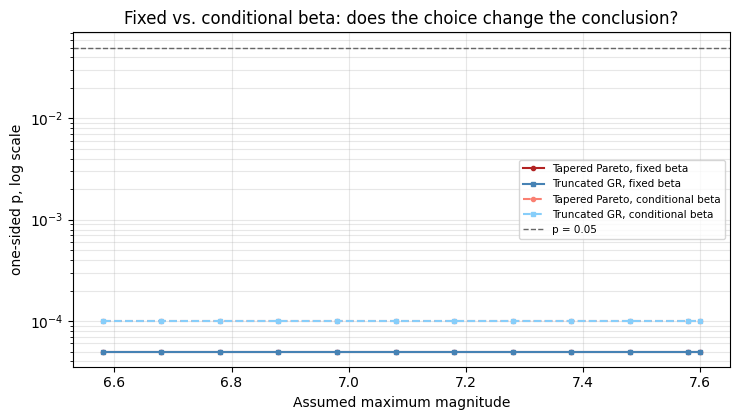

In [20]:
fig, ax = plt.subplots(figsize=(7.5, 4.3))
floor_c = 0.5 / N_MC_CHECK
ax.semilogy(mmax_vals, p_tp_plot, "-o", ms=3, color="firebrick", label="Tapered Pareto, fixed beta")
ax.semilogy(mmax_vals, p_tgr_plot, "-s", ms=3, color="steelblue", label="Truncated GR, fixed beta")
ax.semilogy([r["mmax_mag"] for r in sweep_cond], [max(r["p_tp"], floor_c) for r in sweep_cond],
            "--o", ms=3, color="salmon", label="Tapered Pareto, conditional beta")
ax.semilogy([r["mmax_mag"] for r in sweep_cond], [max(r["p_tgr"], floor_c) for r in sweep_cond],
            "--s", ms=3, color="lightskyblue", label="Truncated GR, conditional beta")
ax.axhline(0.05, color="0.4", ls="--", lw=1, label="p = 0.05")
ax.set_xlabel("Assumed maximum magnitude"); ax.set_ylabel("one-sided p, log scale")
ax.set_title("Fixed vs. conditional beta: does the choice change the conclusion?")
ax.legend(fontsize=7.5); ax.grid(alpha=0.3, which="both")
plt.tight_layout()
fig.savefig(os.path.join(FIG_OUT, "fixed_vs_conditional_beta.png"), dpi=300, bbox_inches="tight")

## 10. Main result

Across two different, independently justified choices of completeness magnitude, two
tail models, fixed and conditional beta, and the full observed-to-UCERF3 range of
assumed maximum off-fault magnitude, the 40-year off-fault seismic moment is
consistently and overwhelmingly below what the geodetic off-fault moment rate
(`mu0 = 1.467968e19 N*m/yr`) would predict, at a significance level beyond what a few thousand
Monte Carlo draws can even resolve. 


## 11. Best-fit tapered Pareto: joint MLE of `beta` and the corner moment

Sections 7-9 treat the tail parameter as a swept assumption. For the inset in Fig. 4 in our manuscript we also show a *best-fitting* tapered Pareto, so here we fit
`beta` and the corner moment $M_{cm}$ jointly by maximum likelihood (Kagan & Schoenberg,
2001), on the same sample (`M >= MIN_FIT_MAGNITUDE`, off-fault, within the California model domain).

The log-likelihood is
$\ell(\beta, M_{cm}) = \sum_i \left[-\beta\ln(m_i/M_t) + (M_t - m_i)/M_{cm} + \ln(\beta/m_i + 1/M_{cm})\right]$.
We optimise over $\log_{10} M_{cm}$ (better conditioned than the moment itself) and show the
profile likelihood, because the corner is known to be weakly constrained by a catalog
whose largest event is only Mw 6.58.

Best-fit tapered Pareto: beta = 0.7002, corner magnitude m_cm = 6.60 (corner moment M_cm = 9.833e+18 N*m)
95% profile interval for m_cm: [6.25, unbounded (> 9.0)]


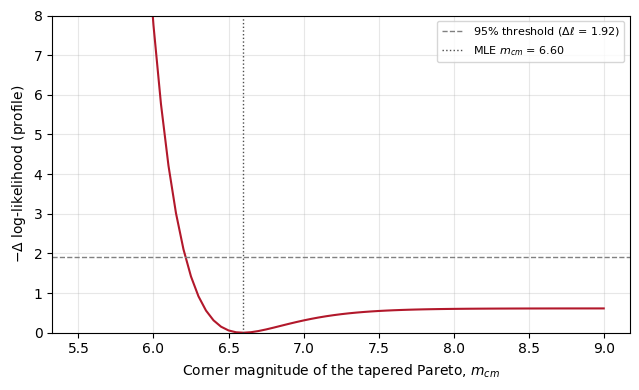

In [21]:
def tapered_negloglik(params, m, Mt):
    beta, log10_Mcm = params
    Mcm = 10.0 ** log10_Mcm
    return -np.sum(-beta * np.log(m / Mt) + (Mt - m) / Mcm + np.log(beta / m + 1.0 / Mcm))

fit_tp = optimize.minimize(tapered_negloglik, x0=[beta_hat, np.log10(mag_to_moment(7.0))],
                           args=(m_fit, Mt), method="Nelder-Mead",
                           options=dict(xatol=1e-7, fatol=1e-7, maxiter=5000))
beta_tp_best, Mcm_tp_best = fit_tp.x[0], 10.0 ** fit_tp.x[1]
mcm_tp_best = moment_to_mag(Mcm_tp_best)
print(f"Best-fit tapered Pareto: beta = {beta_tp_best:.4f}, corner magnitude m_cm = {mcm_tp_best:.2f} "
      f"(corner moment M_cm = {Mcm_tp_best:.3e} N*m)")

# Profile likelihood in the corner magnitude (beta re-optimised at every point)
mcm_profile = np.round(np.arange(5.5, 9.01, 0.05), 2)
nll_profile = np.array([
    optimize.minimize_scalar(lambda b: tapered_negloglik([b, np.log10(mag_to_moment(mm))], m_fit, Mt),
                             bounds=(0.05, 3.0), method="bounded").fun
    for mm in mcm_profile
])
dnll = nll_profile - fit_tp.fun
inside = mcm_profile[dnll <= 1.92]           # 95% profile-likelihood interval (chi2_1 / 2)
upper_open = dnll[-1] <= 1.92
print(f"95% profile interval for m_cm: [{inside.min():.2f}, "
      f"{'unbounded (> ' + format(mcm_profile[-1], '.1f') + ')' if upper_open else format(inside.max(), '.2f')}]")

fig, ax = plt.subplots(figsize=(6.5, 4.0))
ax.plot(mcm_profile, dnll, "-", color="#B2182B")
ax.axhline(1.92, color="0.5", ls="--", lw=1, label="95% threshold ($\\Delta\\ell$ = 1.92)")
ax.axvline(mcm_tp_best, color="0.3", ls=":", lw=1, label=f"MLE $m_{{cm}}$ = {mcm_tp_best:.2f}")
ax.set_xlabel("Corner magnitude of the tapered Pareto, $m_{cm}$")
ax.set_ylabel("$-\\Delta$ log-likelihood (profile)")
ax.set_ylim(0, 8); ax.legend(fontsize=8); ax.grid(alpha=0.3)
plt.tight_layout()
fig.savefig(os.path.join(FIG_OUT, "corner_magnitude_profile.png"), dpi=300, bbox_inches="tight")

The MLE corner sits essentially at the largest observed off-fault event, and the
likelihood is nearly flat above it (the 95% interval is open-ended), as expected for a
40-yr catalog. This is the "best fit" used in the inset; the *extreme case* in the inset
is the truncated GR at UCERF3's off-fault $M_{max}$ = 7.6 (already simulated in Section 9.2), i.e.
the heaviest-tailed bounded model considered in the sweep.

### 11.1 Monte Carlo sampling distribution under H0 for the best-fit tapered Pareto

Same procedure as Section 9.2 (Poisson number of events from the moment budget
$\mu_0 T$, exact rejection sampling, sub-threshold moment added as a fixed term), now with
the jointly fitted `beta` and corner moment.

In [22]:
EM_tp_best = raw_moment_tapered(1.0, Mt, beta_tp_best, Mcm_tp_best)
tot_tp_best = cached_monte_carlo_totals("bestfit_tp", sample_tapered_pareto, Mt, EM_tp_best,
                                        (beta_tp_best, Mcm_tp_best), N_MC_SWEEP)

row_tgr_extreme = sweep[-1]
assert abs(row_tgr_extreme["mmax_mag"] - UCERF3_MAX_OFF_FAULT_MW) < 1e-9
tot_tgr_76 = row_tgr_extreme["tot_tgr"]

for name, tot in [(f"Tapered Pareto, best fit (m_cm={mcm_tp_best:.2f})", tot_tp_best),
                  (f"Truncated GR, Mmax={UCERF3_MAX_OFF_FAULT_MW}", tot_tgr_76)]:
    n_below = int((tot <= M_obs).sum())
    p_txt = f"{n_below / tot.size:.5f}" if n_below else f"< {1 / tot.size:.1e}"
    print(f"{name:45s} median = {np.median(tot):.3e} N*m   "
          f"[2.5, 97.5]% = [{np.percentile(tot, 2.5):.3e}, {np.percentile(tot, 97.5):.3e}]   "
          f"p(sim <= obs) {p_txt}")
print(f"{'Observed':45s} {M_obs:.3e} N*m   (geodetic budget mu0*T = {M_G_null:.3e} N*m)")

# Everything our manuscript figure (Section 12) needs, so it can be redrawn without the cells above
FIGURE_INPUTS_PATH = os.path.join(OUTPUT_DIR, "figure_inputs.npz")   # the shipped copy is in MC_CACHE_DIR
if MC_CACHE_MODE != "off":
    os.makedirs(OUTPUT_DIR, exist_ok=True)
    np.savez_compressed(
        FIGURE_INPUTS_PATH,
        lon=lon, lat=lat, dist_km=dist_km, in_polygon=in_polygon, polygon_lonlat=polygon_lonlat,
        DIST_THRESH_KM=DIST_THRESH_KM, M_obs=M_obs, M_G_null=M_G_null, MU0=MU0, T_years=T_years,
        tot_tp_best=tot_tp_best, tot_tgr_76=tot_tgr_76, beta_tp_best=beta_tp_best,
        Mcm_tp_best=Mcm_tp_best, UCERF3_MAX_OFF_FAULT_MW=UCERF3_MAX_OFF_FAULT_MW,
        N_MC=tot_tp_best.size,
    )
    print(f"Figure inputs saved to {FIGURE_INPUTS_PATH}")

Tapered Pareto, best fit (m_cm=6.60)          median = 5.983e+20 N*m   [2.5, 97.5]% = [4.927e+20, 7.284e+20]   p(sim <= obs) < 1.0e-04
Truncated GR, Mmax=7.6                        median = 5.694e+20 N*m   [2.5, 97.5]% = [2.885e+20, 1.079e+21]   p(sim <= obs) < 1.0e-04
Observed                                      3.538e+19 N*m   (geodetic budget mu0*T = 5.996e+20 N*m)
Figure inputs saved to ../output_data/off_fault_moment_seismic_final/figure_inputs.npz


## 12. Figure 4 in our manuscript

* **Dots:** all events inside the California model domain (dashed outline).
  On-fault events ($d \le$ 5 km) are grey; off-fault events are coloured by
  distance to the nearest NSHM2023 fault plane in 3D, drawn nearest-first so distant events stay
  visible. The colour bar carries the same split: a grey 0-5 km block, `turbo` from 5 km on
  (> 30 km takes the end colour, shown by the triangle).
* **Faults:** the NSHM2023 fault traces, the same geometry the distances were computed to.
* **Inset:** H0 sampling distributions of the 1981-2021 off-fault moment (log axis) for the
  best-fit tapered Pareto (red) and the extreme-case truncated GR with $M_{max}$ = 7.6 (blue);
  the black line is the observed seismic off-fault moment, the dashed line the geodetic budget
  $\mu_0 T$.

In [23]:
import os
import numpy as np

FIGURE_INPUT_NAMES = ["lon", "lat", "dist_km", "in_polygon", "polygon_lonlat", "DIST_THRESH_KM",
                      "M_obs", "M_G_null", "tot_tp_best", "tot_tgr_76", "Mcm_tp_best",
                      "UCERF3_MAX_OFF_FAULT_MW"]

if all(name in globals() for name in FIGURE_INPUT_NAMES):
    print("Figure inputs: using the results computed in this session")
else:
    FIGURE_INPUTS_PATH = os.path.join(globals().get("MC_CACHE_DIR", "mc_cache"), "figure_inputs.npz")
    with np.load(FIGURE_INPUTS_PATH) as saved:
        for name in FIGURE_INPUT_NAMES:
            globals()[name] = saved[name] if saved[name].ndim else saved[name].item()
    if "moment_to_mag" not in globals():
        def moment_to_mag(moment):
            return (np.log10(moment) - 9.1) / 1.5
    print(f"Figure inputs loaded from {FIGURE_INPUTS_PATH} "
          f"({tot_tp_best.size:,} Monte Carlo draws per distribution)")

Figure inputs: using the results computed in this session


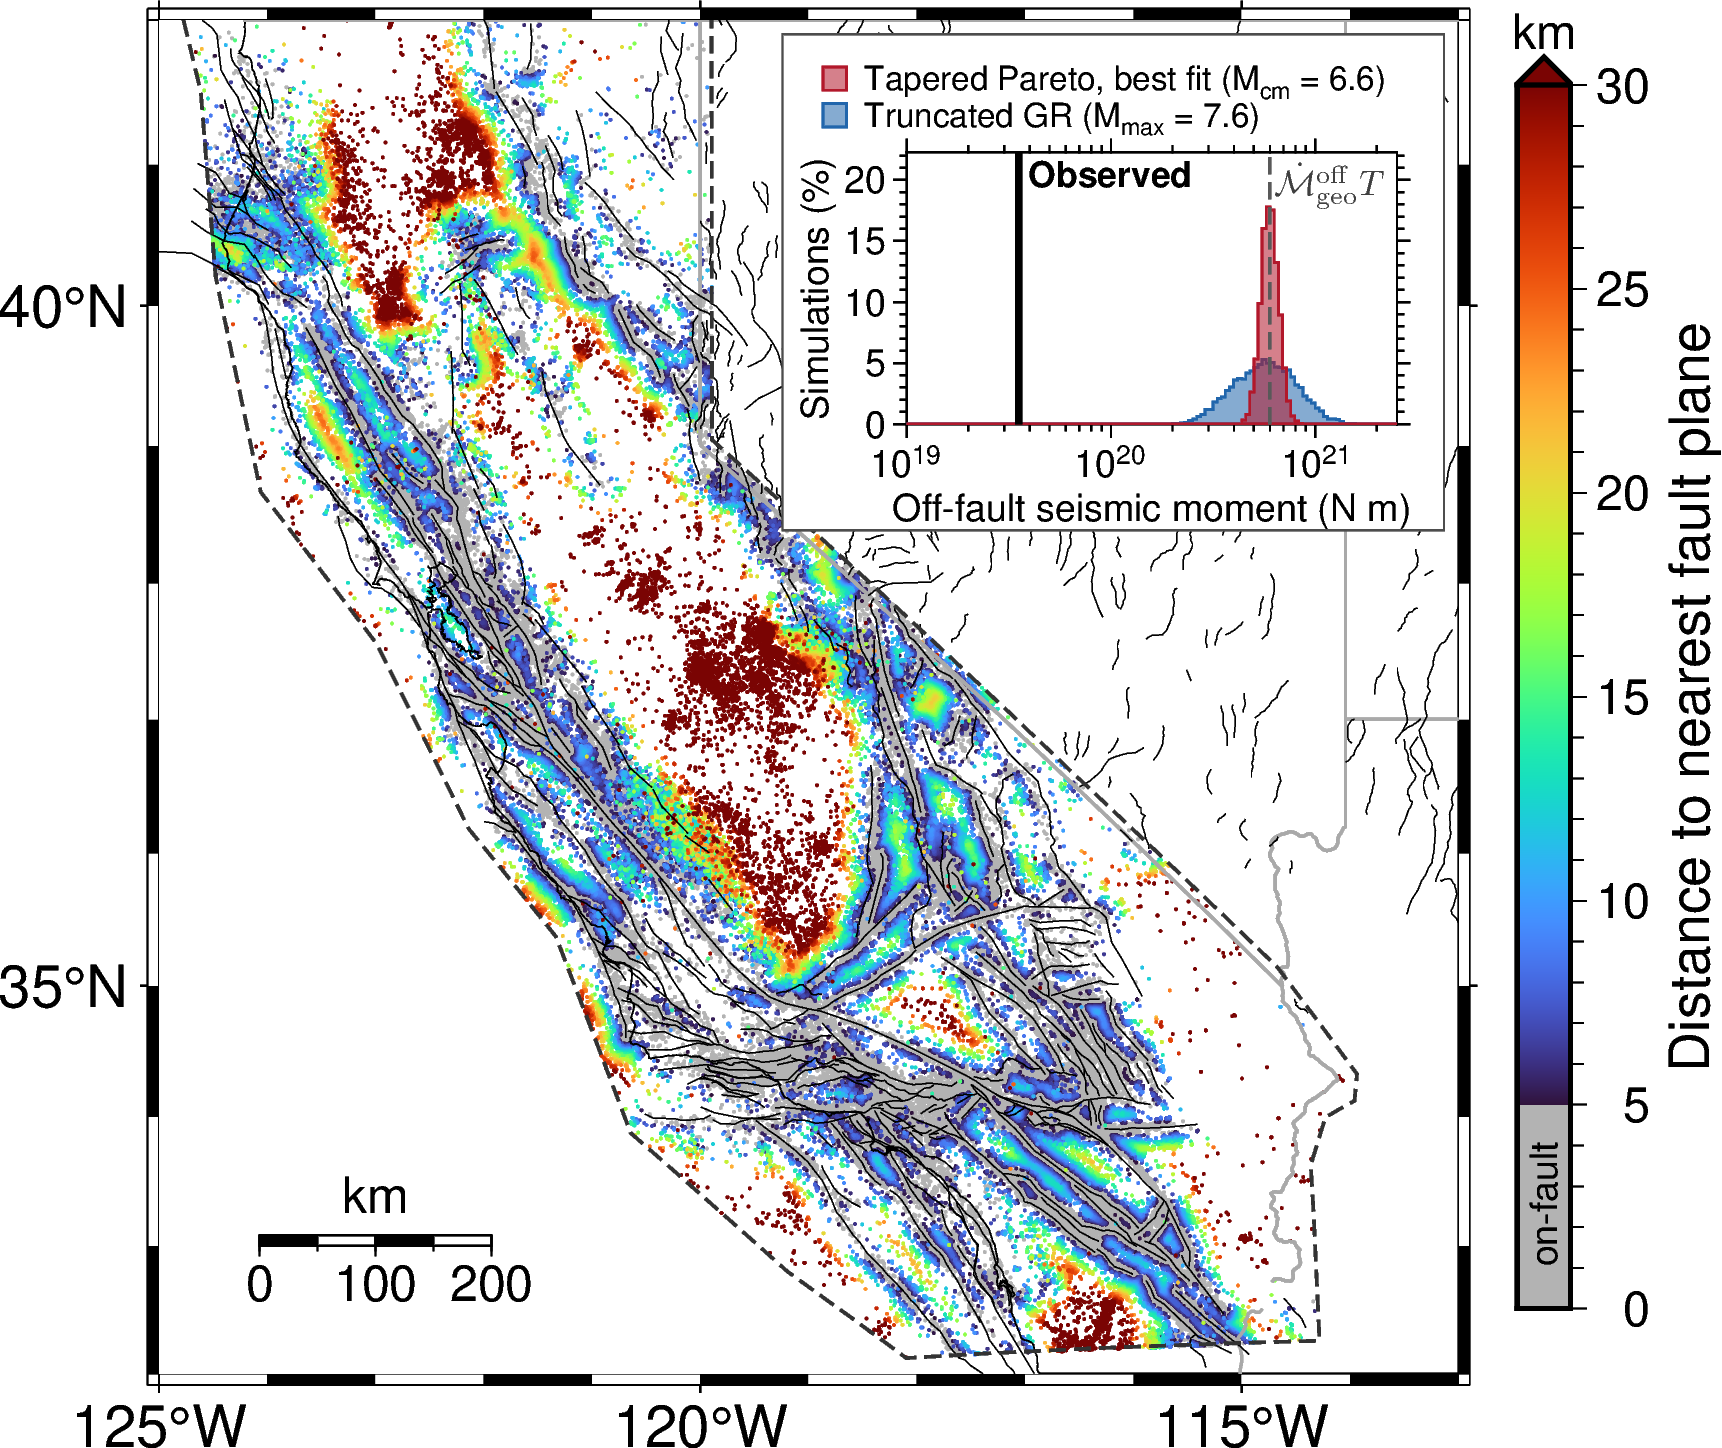

In [24]:
import os
import pygmt
import pandas as pd

# =============================================================================
# CONFIGURATION
# =============================================================================
FIG_DIR = FIG_OUT
os.makedirs(FIG_DIR, exist_ok=True)
output_prefix = "CALI_off_fault_seismicity"

NSHM_FAULT_CSV = os.path.join(INPUT_DIR, "NSHM2023_FaultSections_v1p4.csv")
nshm_trace_file = f"{FIG_DIR}/NSHM2023_fault_traces.gmt"
distance_cpt_file = f"{FIG_DIR}/fault_distance.cpt"

region = [-125, -113, 32, 42]       # California (lon_min, lon_max, lat_min, lat_max)
map_width_cm = 11                   # projection='M11c'
map_projection = f"M{map_width_cm}c"

# Earthquake symbols: on-fault events in a neutral grey, off-fault events coloured by distance
eq_symbol_style = "c0.03c"
on_fault_color = "gray70"
range_distance_offfault = [DIST_THRESH_KM, 30]   # turbo spans the off-fault range; > 30 km uses the end colour

# Plot styling
colorbar_width = 0.45               # cm (bar thickness)
ocean_fill_color = "white"
shorelines_pen = "0.3p,black"
borders_pen = "2/0.75p,darkgray,solid"
faults_pen = "0.25p,black"
polygon_pen = "0.8p,gray20,4_2:0p"
map_scale_bar_length_km = 200
map_scale_bar_position = [-123, 33]   # (lon, lat)

# Inset (upper-right corner, NE of the CA-NV border where no events are plotted)
inset_size_cm = [5.6, 4.2]
inset_offset_cm = [0.12, 0.12]
inset_margin_cm = [1.05, 0.4, 0.9, 1.0]   # left, right, bottom, top (room for axes labels + legend)
color_tp = "#B2182B"     # tapered Pareto (red, as in the sweep figures)
color_tgr = "#2166AC"    # truncated GR (blue, as in the sweep figures)
hist_bin_width_log10 = 0.02
save_fig = True

# =============================================================================
# NSHM2023 fault traces -> GMT multisegment file (same traces the distances were computed to)
# =============================================================================
faults_df = pd.read_csv(NSHM_FAULT_CSV)
with open(nshm_trace_file, "w") as fh:
    for _, row in faults_df.iterrows():
        xy = np.array(str(row["coordinates"]).split(","), dtype=float)
        if xy.size < 4 or xy.size % 2:
            continue
        xy = xy.reshape(-1, 2)
        fh.write(f"> {row['FaultName']}\n")
        np.savetxt(fh, xy, fmt="%.5f")

# =============================================================================
# Colour palette: grey for on-fault (<= threshold), turbo for off-fault distances
# =============================================================================
pygmt.makecpt(cmap="turbo", series=range_distance_offfault + [0.5], continuous=True,
              background="o", output=distance_cpt_file)
with open(distance_cpt_file) as fh:
    cpt_lines = fh.readlines()
first_slice = next(i for i, line in enumerate(cpt_lines)
                   if line.strip() and not line.startswith("#"))
cpt_lines.insert(first_slice, f"0\t{on_fault_color}\t{DIST_THRESH_KM:g}\t{on_fault_color}\n")
with open(distance_cpt_file, "w") as fh:
    fh.writelines(cpt_lines)

# =============================================================================
# Earthquakes inside the strain polygon (the analysis domain)
# =============================================================================
on_fault_map = in_polygon & (dist_km <= DIST_THRESH_KM)
off_fault_map = in_polygon & (dist_km > DIST_THRESH_KM)
order = np.argsort(dist_km[off_fault_map])        # draw far events last, so they are not buried
off_lon = lon[off_fault_map][order]
off_lat = lat[off_fault_map][order]
off_dist = dist_km[off_fault_map][order]

# Map height (Mercator) -> used to place the "on-fault" label on the colour bar
def _merc_y(phi_deg):
    return np.log(np.tan(np.pi / 4 + np.radians(phi_deg) / 2))
map_height_cm = map_width_cm * (_merc_y(region[3]) - _merc_y(region[2])) / np.radians(region[1] - region[0])
colorbar_length = round(0.9 * map_height_cm, 2)

# =============================================================================
# Map
# =============================================================================
fig = pygmt.Figure()
with pygmt.config(FONT_ANNOT_PRIMARY="14p"):
    fig.basemap(region=region, projection=map_projection, frame="af")

fig.coast(water=ocean_fill_color, area_thresh=4000, resolution="h")

fig.plot(x=lon[on_fault_map], y=lat[on_fault_map], style=eq_symbol_style,
         fill=on_fault_color, pen=None)
fig.plot(x=off_lon, y=off_lat, style=eq_symbol_style, fill=off_dist,
         cmap=distance_cpt_file, pen=None)

fig.coast(shorelines=shorelines_pen, area_thresh=4000, resolution="h", borders=borders_pen)
fig.plot(data=nshm_trace_file, pen=faults_pen)
fig.plot(x=np.append(polygon_lonlat[:, 0], polygon_lonlat[0, 0]),
         y=np.append(polygon_lonlat[:, 1], polygon_lonlat[0, 1]), pen=polygon_pen)

with pygmt.config(
    FONT_ANNOT_PRIMARY="14p",     # tick labels
    FONT_ANNOT_SECONDARY="14p",
    FONT_LABEL="16p",             # axis labels
):
    fig.colorbar(
        cmap=distance_cpt_file,
        frame=["xa5f1+lDistance to nearest fault plane", "y+lkm"],
        position=f"JMR+o0.5c/0c+w{colorbar_length}c/{colorbar_width}c+v+ef",
    )

with pygmt.config(FONT_ANNOT_PRIMARY="12p", FONT_LABEL="12p"):
    fig.basemap(map_scale=f"g{map_scale_bar_position[0]}/{map_scale_bar_position[1]}"
                          f"+w{map_scale_bar_length_km}k+f+lkm")

# -----------------------------------------------------------------------------
# INSET: null-hypothesis sampling distributions vs. the observed off-fault moment
# -----------------------------------------------------------------------------
log_tp = np.log10(tot_tp_best)
log_tgr = np.log10(tot_tgr_76)
log_obs = np.log10(M_obs)
log_budget = np.log10(M_G_null)

x_lo = np.floor(log_obs - 0.1)                       # start at a full decade (10^19) left of the observation
x_hi = np.ceil((max(np.percentile(log_tgr, 99.5), log_tp.max()) + 0.2) * 10) / 10
bin_edges = np.arange(x_lo, x_hi + hist_bin_width_log10, hist_bin_width_log10)

def _step_polygon(log_values):
    counts, _ = np.histogram(np.clip(log_values, x_lo, x_hi), bins=bin_edges)
    pct = 100.0 * counts / log_values.size
    xs = np.repeat(bin_edges, 2)[1:-1]
    ys = np.repeat(pct, 2)
    return 10 ** np.r_[bin_edges[0], xs, bin_edges[-1]], np.r_[0, ys, 0], pct.max()

x_tp, y_tp, ymax_tp = _step_polygon(log_tp)
x_tgr, y_tgr, ymax_tgr = _step_polygon(log_tgr)
y_top = 1.25 * max(ymax_tp, ymax_tgr)

hist_w = inset_size_cm[0] - inset_margin_cm[0] - inset_margin_cm[1]
hist_h = inset_size_cm[1] - inset_margin_cm[2] - inset_margin_cm[3]
hist_region = [10 ** x_lo, 10 ** x_hi, 0, y_top]
hist_projection = f"X{hist_w}cl/{hist_h}c"

corner_mag_tp = moment_to_mag(Mcm_tp_best)
inset_clearance_kw = "clearance" if tuple(int(v) for v in pygmt.__version__.lstrip("v").split(".")[:2]) >= (0, 18) else "margin"
legend_spec = f"{FIG_DIR}/inset_legend.txt"
with open(legend_spec, "w") as fh:
    fh.write(f"S 0.2c s 0.28c {color_tp}@45 0.6p,{color_tp} 0.45c "
             f"Tapered Pareto, best fit (M@-cm@- = {corner_mag_tp:.1f})\n")
    fh.write(f"S 0.2c s 0.28c {color_tgr}@45 0.6p,{color_tgr} 0.45c "
             f"Truncated GR (M@-max@- = {UCERF3_MAX_OFF_FAULT_MW:.1f})\n")

with fig.inset(
    position=f"jTR+w{inset_size_cm[0]}c/{inset_size_cm[1]}c+o{inset_offset_cm[0]}c/{inset_offset_cm[1]}c",
    box="+gwhite+p0.5p,gray30",
    **{inset_clearance_kw: inset_margin_cm},
):
    with pygmt.config(FONT_ANNOT_PRIMARY="9p", FONT_LABEL="9p", MAP_LABEL_OFFSET="4p",
                      MAP_ANNOT_OFFSET_PRIMARY="2p", MAP_FRAME_PEN="0.5p,black",
                      MAP_TICK_PEN_PRIMARY="0.5p,black", MAP_TICK_LENGTH_PRIMARY="3p",
                      MAP_FRAME_TYPE="plain"):
        fig.basemap(region=hist_region, projection=hist_projection,
                    frame=["WSne", "xa1pf3+lOff-fault seismic moment (N m)",
                           "yaf+lSimulations (%)"])
        fig.plot(x=x_tgr, y=y_tgr, fill=f"{color_tgr}@45", pen=f"0.6p,{color_tgr}", close=True)
        fig.plot(x=x_tp, y=y_tp, fill=f"{color_tp}@45", pen=f"0.6p,{color_tp}", close=True)

        fig.plot(x=[M_G_null, M_G_null], y=[0, y_top], pen="0.8p,gray35,4_2:0p")
        fig.plot(x=[M_obs, M_obs], y=[0, y_top], pen="1.6p,black")
        fig.text(x=M_obs, y=0.97 * y_top, text="Observed", font="8.5p,Helvetica-Bold,black",
                 justify="TL", offset="0.08c/0c")
        fig.text(x=M_G_null, y=0.97 * y_top, text=r"<math>\dot{\mathcal{M}}_{\mathrm{geo}}^{\mathrm{off}}T</math>", font="8.5p,Helvetica,gray25",
                 justify="TL", offset="0.01c/0c")

        with pygmt.config(FONT_ANNOT_PRIMARY="8p"):
            fig.legend(spec=legend_spec, position=f"jTL+o-{inset_margin_cm[0] - 0.1}c/-{inset_margin_cm[3] - 0.08}c+w{inset_size_cm[0] - 0.2}c",
                       box=False)

# "On-fault" tag inside the grey part of the colour bar (paper coordinates of the map frame)
cb_y0 = 0.5 * (map_height_cm - colorbar_length)
fig.text(x=map_width_cm + 0.5 + colorbar_width / 2,
         y=cb_y0 + 0.5 * colorbar_length * DIST_THRESH_KM / range_distance_offfault[1],
         text="on-fault", angle=90, font="9p,Helvetica,black", justify="CM",
         region=[0, map_width_cm, 0, map_height_cm], projection=f"X{map_width_cm}c/{map_height_cm}c",
         no_clip=True)

if save_fig:
    fig.savefig(f"{FIG_DIR}/{output_prefix}_map.pdf", dpi=600)
    fig.savefig(f"{FIG_DIR}/{output_prefix}_map.png", dpi=600)
fig.show()